In [1]:
from pathlib import Path
import copy, json, os, random, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights

DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)

C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Confirming CUDA is being used

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", GPU_NAME)
print("Device:", DEVICE)

PyTorch: 2.14.0+cu130
CUDA: 13.0
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Device: cuda


## 2. Reproducibility and project paths

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models" / "resnet50_hparam"
REPORT_DIR = PROJECT_ROOT / "reports" / "resnet50_hparam"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development


## 3. Loading baseline split

In [4]:
df = pd.read_csv(
    DATA_DIR / "interim" / "compcars_resnet50_baseline_split.csv"
)

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

NUM_CLASSES = df["target"].nunique()
class_names = (
    df[["target", "class_name"]]
    .drop_duplicates()
    .sort_values("target")["class_name"]
    .tolist()
)

print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))
print("Classes:", NUM_CLASSES)

Train / Val / Test: 1600 200 200
Classes: 20


## 4. Configuring CompCars image path

In [5]:
DEFAULT_COMPCARS = (
    r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J"
    r"\capstone-vehicle-metadata\data\compcars_kaggle\extracted"
)

ROOT = Path(os.environ.get("COMPCARS_EXTRACTED", DEFAULT_COMPCARS))

if not ROOT.exists():
    raise FileNotFoundError(f"CompCars path does not exist:\n{ROOT}")

def resolve_local_path(original_path):
    text = str(original_path).replace("\\", "/")
    if "/extracted/" in text:
        relative = text.split("/extracted/", 1)[1]
    elif "/image/" in text:
        relative = "image/" + text.split("/image/", 1)[1]
    else:
        return Path(original_path)
    return ROOT / Path(*relative.split("/"))

for part in [train_df, val_df, test_df]:
    part["local_file_path"] = part["file_path"].map(resolve_local_path)

sample = pd.concat([train_df, val_df, test_df]).sample(30, random_state=SEED)
if not sample["local_file_path"].map(Path.exists).all():
    raise FileNotFoundError("Some image paths do not resolve.")

print("Image path mapping looks good.")

Image path mapping looks good.


## 5. Hyperparameter configuration

In [6]:
EXPERIMENTS = [
    {"name":"baseline","finetune_lr":1e-4,"weight_decay":1e-4,"unfreeze_depth":"layer4","label_smoothing":0.1,"augmentation":"standard","stage2_epochs":3},
    {"name":"lr_1e-5","finetune_lr":1e-5,"weight_decay":1e-4,"unfreeze_depth":"layer4","label_smoothing":0.1,"augmentation":"standard","stage2_epochs":3},
    {"name":"lr_5e-5","finetune_lr":5e-5,"weight_decay":1e-4,"unfreeze_depth":"layer4","label_smoothing":0.1,"augmentation":"standard","stage2_epochs":3},
    {"name":"lr_5e-4","finetune_lr":5e-4,"weight_decay":1e-4,"unfreeze_depth":"layer4","label_smoothing":0.1,"augmentation":"standard","stage2_epochs":3},
    {"name":"unfreeze_layer3_layer4","finetune_lr":5e-5,"weight_decay":1e-4,"unfreeze_depth":"layer3_layer4","label_smoothing":0.1,"augmentation":"standard","stage2_epochs":3},
    {"name":"no_label_smoothing","finetune_lr":1e-4,"weight_decay":1e-4,"unfreeze_depth":"layer4","label_smoothing":0.0,"augmentation":"standard","stage2_epochs":3},
    {"name":"strong_augmentation","finetune_lr":1e-4,"weight_decay":1e-4,"unfreeze_depth":"layer4","label_smoothing":0.1,"augmentation":"strong","stage2_epochs":3},
    {"name":"weight_decay_1e-5","finetune_lr":1e-4,"weight_decay":1e-5,"unfreeze_depth":"layer4","label_smoothing":0.1,"augmentation":"standard","stage2_epochs":3},
    {"name":"longer_finetune","finetune_lr":5e-5,"weight_decay":1e-4,"unfreeze_depth":"layer3_layer4","label_smoothing":0.1,"augmentation":"standard","stage2_epochs":6},
]

display(pd.DataFrame(EXPERIMENTS))

,name,finetune_lr,weight_decay,unfreeze_depth,label_smoothing,augmentation,stage2_epochs
0,baseline,0.00010,0.00010,layer4,0.1,standard,3
1,lr_1e-5,0.00001,0.00010,layer4,0.1,standard,3
2,lr_5e-5,0.00005,0.00010,layer4,0.1,standard,3
3,lr_5e-4,0.00050,0.00010,layer4,0.1,standard,3
4,unfreeze_layer3_layer4,0.00005,0.00010,layer3_layer4,0.1,standard,3
5,no_label_smoothing,0.00010,0.00010,layer4,0.0,standard,3
6,strong_augmentation,0.00010,0.00010,layer4,0.1,strong,3
7,weight_decay_1e-5,0.00010,0.00001,layer4,0.1,standard,3
8,longer_finetune,0.00005,0.00010,layer3_layer4,0.1,standard,6


## 6. Transformations and dataset

In [7]:
IMAGE_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def make_train_transform(kind):
    if kind == "standard":
        return transforms.Compose([
            transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.80, 1.0), ratio=(0.85, 1.15)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    if kind == "strong":
        return transforms.Compose([
            transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.70, 1.0), ratio=(0.80, 1.20)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(5),
            transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.20, hue=0.03),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
            transforms.RandomErasing(p=0.20, scale=(0.02, 0.10)),
        ])
    raise ValueError(kind)

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class CompCarsDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, index):
        row = self.df.iloc[index]
        image = Image.open(row["local_file_path"]).convert("RGB")
        return self.transform(image), int(row["target"])

## 7. DataLoaders

In [10]:
BATCH_SIZE = 32
NUM_WORKERS = 0

def make_loaders(augmentation):
    train_loader = DataLoader(
        CompCarsDataset(train_df, make_train_transform(augmentation)),
        batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=True,
    )
    val_loader = DataLoader(
        CompCarsDataset(val_df, eval_transform),
        batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=True,
    )
    test_loader = DataLoader(
        CompCarsDataset(test_df, eval_transform),
        batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=True,
    )
    return train_loader, val_loader, test_loader

print("Batch size:", BATCH_SIZE)

Batch size: 32


## 8. Building the ResNet50 model

In [11]:
def build_resnet50():
    model = resnet50(weights=ResNet50_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(DEVICE)

def configure_stage2_unfreezing(model, depth):
    for p in model.fc.parameters():
        p.requires_grad = True

    if depth == "layer4":
        modules = [model.layer4]
    elif depth == "layer3_layer4":
        modules = [model.layer3, model.layer4]
    else:
        raise ValueError(depth)

    for module in modules:
        for p in module.parameters():
            p.requires_grad = True

## 9. Training utilities

In [12]:
def topk_correct(logits, targets, k=5):
    k = min(k, logits.shape[1])
    return logits.topk(k, dim=1).indices.eq(
        targets.view(-1, 1)
    ).any(dim=1).sum().item()

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    top1_correct = 0
    top5_correct = 0
    samples = 0

    for images, targets in tqdm(loader, leave=False):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=True):
            logits = model(images)
            loss = criterion(logits, targets)

        if training:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        bs = images.size(0)
        total_loss += loss.item() * bs
        top1_correct += (logits.argmax(1) == targets).sum().item()
        top5_correct += topk_correct(logits, targets, 5)
        samples += bs

    return {
        "loss": total_loss / samples,
        "top1": top1_correct / samples,
        "top5": top5_correct / samples,
    }

def train_epochs(model, train_loader, val_loader, criterion, optimizer, epochs, stage_name):
    scaler = torch.amp.GradScaler("cuda", enabled=True)
    history = []
    best_val = -1.0
    best_state = None

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()

        train_metrics = run_epoch(model, train_loader, criterion, optimizer, scaler)
        with torch.inference_mode():
            val_metrics = run_epoch(model, val_loader, criterion)

        elapsed = time.perf_counter() - start
        row = {
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_top1": train_metrics["top1"],
            "val_loss": val_metrics["loss"],
            "val_top1": val_metrics["top1"],
            "val_top5": val_metrics["top5"],
            "seconds": elapsed,
        }
        history.append(row)

        print(
            f"[{stage_name}] {epoch}/{epochs} | "
            f"train={row['train_top1']:.3f} "
            f"val={row['val_top1']:.3f} "
            f"top5={row['val_top5']:.3f} | "
            f"{elapsed:.1f}s"
        )

        if row["val_top1"] > best_val:
            best_val = row["val_top1"]
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return history, best_val, best_state

## 10. Running hyperparameter search

In [13]:
STAGE1_EPOCHS = 3
HEAD_LR = 1e-3

search_results = []

for config in EXPERIMENTS:
    print("\n" + "=" * 80)
    print("EXPERIMENT:", config["name"])
    print(config)
    print("=" * 80)

    train_loader, val_loader, _ = make_loaders(config["augmentation"])
    model = build_resnet50()

    criterion = nn.CrossEntropyLoss(
        label_smoothing=config["label_smoothing"]
    )

    optimizer = torch.optim.AdamW(
        model.fc.parameters(),
        lr=HEAD_LR,
        weight_decay=config["weight_decay"],
    )

    history1, val1, state1 = train_epochs(
        model, train_loader, val_loader,
        criterion, optimizer, STAGE1_EPOCHS, "head"
    )

    configure_stage2_unfreezing(model, config["unfreeze_depth"])

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=config["finetune_lr"],
        weight_decay=config["weight_decay"],
    )

    history2, val2, state2 = train_epochs(
        model, train_loader, val_loader,
        criterion, optimizer,
        config["stage2_epochs"], "fine_tune"
    )

    if val1 > val2:
        selected_stage = "head"
        selected_val = val1
        selected_state = state1
    else:
        selected_stage = "fine_tune"
        selected_val = val2
        selected_state = state2

    checkpoint_path = MODEL_DIR / f"{config['name']}_best.pt"

    torch.save(
        {
            "state_dict": selected_state,
            "config": config,
            "validation_top1": float(selected_val),
            "selected_stage": selected_stage,
            "classes": class_names,
            "num_classes": NUM_CLASSES,
        },
        checkpoint_path,
    )

    search_results.append({
        **config,
        "selected_stage": selected_stage,
        "validation_top1": selected_val,
        "checkpoint": str(checkpoint_path),
        "total_seconds": sum(row["seconds"] for row in history1 + history2),
    })

    del model
    torch.cuda.empty_cache()

search_df = pd.DataFrame(search_results).sort_values(
    "validation_top1", ascending=False
).reset_index(drop=True)

display(search_df)

search_df.to_csv(
    REPORT_DIR / "hyperparameter_search.csv",
    index=False,
)


EXPERIMENT: baseline
{'name': 'baseline', 'finetune_lr': 0.0001, 'weight_decay': 0.0001, 'unfreeze_depth': 'layer4', 'label_smoothing': 0.1, 'augmentation': 'standard', 'stage2_epochs': 3}
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\elesh/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 63.1MB/s]


[head] 1/3 | train=0.185 val=0.335 top5=0.740 | 72.5s


[head] 2/3 | train=0.520 val=0.425 top5=0.805 | 52.1s


[head] 3/3 | train=0.650 val=0.465 top5=0.830 | 53.3s


...

[fine_tune] 3/6 | train=0.968 val=0.705 top5=0.935 | 43.2s


[fine_tune] 4/6 | train=0.994 val=0.710 top5=0.940 | 43.1s


[fine_tune] 5/6 | train=0.997 val=0.740 top5=0.940 | 43.2s


[fine_tune] 6/6 | train=0.998 val=0.740 top5=0.940 | 43.2s


,name,finetune_lr,weight_decay,unfreeze_depth,label_smoothing,augmentation,stage2_epochs,selected_stage,validation_top1,checkpoint,total_seconds
0,lr_5e-4,0.00050,0.00010,layer4,0.1,standard,3,fine_tune,0.825,C:\Users\elesh\Academics\UTS\36127InnovationLa...,312.005056
1,weight_decay_1e-5,0.00010,0.00001,layer4,0.1,standard,3,fine_tune,0.770,C:\Users\elesh\Academics\UTS\36127InnovationLa...,252.626680
2,strong_augmentation,0.00010,0.00010,layer4,0.1,strong,3,fine_tune,0.755,C:\Users\elesh\Academics\UTS\36127InnovationLa...,284.004549
3,unfreeze_layer3_layer4,0.00005,0.00010,layer3_layer4,0.1,standard,3,fine_tune,0.750,C:\Users\elesh\Academics\UTS\36127InnovationLa...,294.274062
4,longer_finetune,0.00005,0.00010,layer3_layer4,0.1,standard,6,fine_tune,0.740,C:\Users\elesh\Academics\UTS\36127InnovationLa...,383.991333
5,baseline,0.00010,0.00010,layer4,0.1,standard,3,fine_tune,0.725,C:\Users\elesh\Academics\UTS\36127InnovationLa...,334.974993
6,no_label_smoothing,0.00010,0.00010,layer4,0.0,standard,3,fine_tune,0.725,C:\Users\elesh\Academics\UTS\36127InnovationLa...,293.980677
7,lr_5e-5,0.00005,0.00010,layer4,0.1,standard,3,fine_tune,0.665,C:\Users\elesh\Academics\UTS\36127InnovationLa...,293.485642
8,lr_1e-5,0.00001,0.00010,layer4,0.1,standard,3,fine_tune,0.485,C:\Users\elesh\Academics\UTS\36127InnovationLa...,283.700501


## 11. Best validation configuration

In [14]:
best = search_df.iloc[0]
display(best.to_frame().T)

,name,finetune_lr,weight_decay,unfreeze_depth,label_smoothing,augmentation,stage2_epochs,selected_stage,validation_top1,checkpoint,total_seconds
0,lr_5e-4,0.0005,0.0001,layer4,0.1,standard,3,fine_tune,0.825,C:\Users\elesh\Academics\UTS\36127InnovationLa...,312.005056


## 12. Final held-out test evaluation

In [15]:
best_config = {
    "name": str(best["name"]),
    "finetune_lr": float(best["finetune_lr"]),
    "weight_decay": float(best["weight_decay"]),
    "unfreeze_depth": str(best["unfreeze_depth"]),
    "label_smoothing": float(best["label_smoothing"]),
    "augmentation": str(best["augmentation"]),
    "stage2_epochs": int(best["stage2_epochs"]),
}

_, _, test_loader = make_loaders(best_config["augmentation"])

model = build_resnet50()
checkpoint = torch.load(best["checkpoint"], map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["state_dict"])
model.eval()

y_true, y_pred, probs_all = [], [], []

with torch.inference_mode():
    for images, targets in tqdm(test_loader):
        images = images.to(DEVICE, non_blocking=True)
        probs = torch.softmax(model(images), dim=1)

        y_true.extend(targets.numpy())
        y_pred.extend(probs.argmax(1).cpu().numpy())
        probs_all.append(probs.cpu())

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
probs_all = torch.cat(probs_all)

top1 = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
top5_idx = probs_all.topk(5, dim=1).indices.numpy()
top5 = np.mean([
    true in candidates
    for true, candidates in zip(y_true, top5_idx)
])

print(f"Best config Test Top-1: {top1:.4f}")
print(f"Best config Test Top-5: {top5:.4f}")
print(f"Best config Macro F1:   {macro_f1:.4f}")

100%|██████████| 7/7 [00:04<00:00,  1.66it/s]

Best config Test Top-1: 0.8350
Best config Test Top-5: 0.9800
Best config Macro F1:   0.8350


,precision,recall,f1-score,support
Audi | Audi A5 coupe,0.583333,0.700,0.636364,10.000
Audi | Audi A5 hatchback,0.555556,0.500,0.526316,10.000
Audi | Audi A8L,0.833333,1.000,0.909091,10.000
BAW | BAW E Series hatchback,0.900000,0.900,0.900000,10.000
BWM | BWM 3 Series,1.000000,0.800,0.888889,10.000
BWM | BWM 5 Series,0.818182,0.900,0.857143,10.000
Benz | Benz E Class,1.000000,0.700,0.823529,10.000
Benz | Benz E Class couple,0.666667,1.000,0.800000,10.000
Buck | EXCELLE GT,0.818182,0.900,0.857143,10.000
Buck | Lacrosse,1.000000,1.000,1.000000,10.000


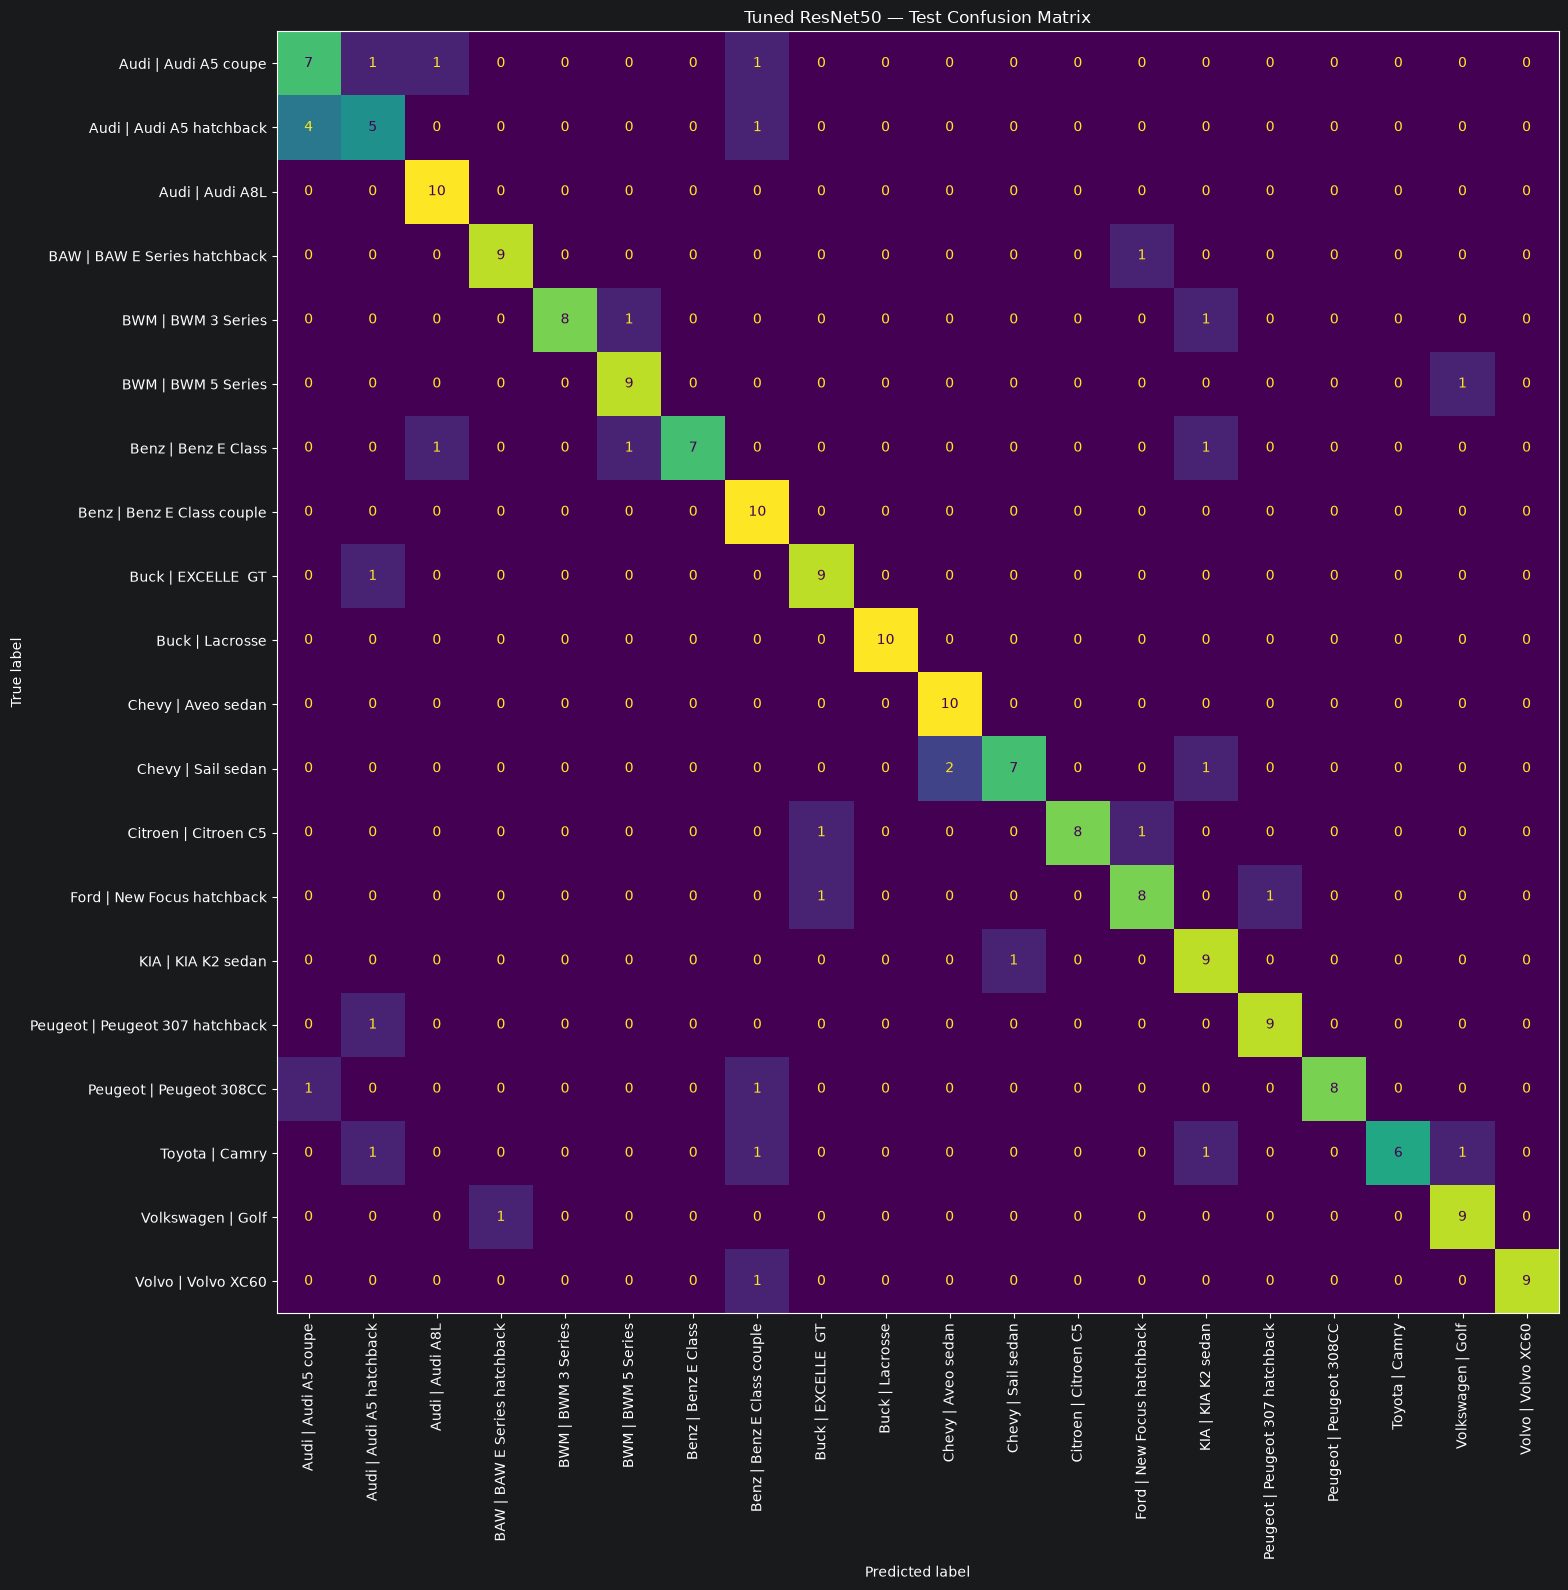

In [16]:
report_df = pd.DataFrame(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
).T

report_df.to_csv(
    REPORT_DIR / "best_config_classification_report.csv"
)

display(report_df)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
)

fig, ax = plt.subplots(figsize=(16, 16))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
).plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d",
)

ax.set_title("Tuned ResNet50 — Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    REPORT_DIR / "best_config_confusion_matrix.png",
    dpi=160,
)
plt.show()

## 14. Saving best tuned ResNet50

In [17]:
def json_converter(obj):
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    raise TypeError(
        f"Object of type {type(obj).__name__} is not JSON serializable"
    )

final_model_path = MODEL_DIR / "resnet50_best_tuned.pt"

torch.save(
    {
        "architecture": "resnet50",
        "state_dict": model.state_dict(),
        "classes": class_names,
        "num_classes": NUM_CLASSES,
        "best_config": best_config,
        "validation_top1": float(best["validation_top1"]),
        "test_top1": float(top1),
        "test_top5": float(top5),
        "test_macro_f1": float(macro_f1),
        "gpu": GPU_NAME,
    },
    final_model_path,
)

final_metrics = {
    "architecture": "ResNet50",
    "best_config": best_config,
    "validation_top1": float(best["validation_top1"]),
    "test_top1": float(top1),
    "test_top5": float(top5),
    "test_macro_f1": float(macro_f1),
    "gpu": GPU_NAME,
}

with (REPORT_DIR / "best_config_metrics.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(
        final_metrics,
        f,
        indent=2,
        default=json_converter,
    )

print("Saved model:", final_model_path)
final_metrics

Saved model: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\models\resnet50_hparam\resnet50_best_tuned.pt


{'architecture': 'ResNet50',
 'best_config': {'name': 'lr_5e-4',
  'finetune_lr': 0.0005,
  'weight_decay': 0.0001,
  'unfreeze_depth': 'layer4',
  'label_smoothing': 0.1,
  'augmentation': 'standard',
  'stage2_epochs': 3},
 'validation_top1': 0.825,
 'test_top1': 0.835,
 'test_top5': 0.98,
 'test_macro_f1': 0.8350120394180832,
 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU'}